# Rainbow Bead Calibration

In this example, we have the data from our paper that was recorded with two 23 marker panels on a BD A3. While we use results for both the Identity and TCell panels in the paper, this tutorial is limited to the TCell panel.

As before, the first step is to calibrate the flow cytometer.

In [1]:
import numpy as np
import pandas as pd
import anndata
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os
import PIL

#import cytovanni

import sys
local_path = os.path.expanduser("~/cytovanni_publish/Cytovanni/src")
if local_path not in sys.path:
    sys.path.insert(0, local_path)
import cytovanni
cytovanni.__version__

'1.1.0'

In [2]:
raw_data_path = os.path.expanduser("~/Cytovanni/data/example_variable-spectra/")
data_path = os.path.expanduser("~/Cytovanni/docs/tutorials/integration_variable-spectra/")

We strongly suggest using a GPU for speedup.

In [3]:
import torch
device = "cuda:0" if torch.cuda.is_available() else "cpu"
print(device)

cuda:0


In [4]:
cytoconfig = cytovanni.utils.CytometerConfiguration_A3()

## Cytometer Calibration

### Prepare Data

We first collect all the necessary metadata of the rainbow bead measurements.

In [7]:
meta = pd.read_table(os.path.join(raw_data_path, "raw_fcs", "meta_Rainbow.csv"), sep=",", index_col=0)
meta["type_rb"] = meta["type_rb"].astype(str) # important, rainbow type has to be string for consistency!
meta

,filepath,batch_rb,date,type_rb,month,year,type_rb_Npeak,begin_record,begin_record_s
0,HD7_202106_Proteona/HD7Tcell20210621/Samples_B...,20210621_tcell_B,20210621,1055831,202106,2021,8,13:52:12,49932
1,HD7_202106_Proteona/HD7Tcell20210621/Samples_C...,20210621_tcell_C,20210621,1055831,202106,2021,8,16:06:07,57967
2,HD7_202106_Proteona/HD7identity20210621/Sample...,20210621_identity_E,20210621,1055831,202106,2021,8,17:48:55,64135
3,HD7_202107/HD7Tcellpanel20210706/Batch A_Rainb...,20210706_tcell_A,20210706,1055831,202107,2021,8,11:26:07,41167
4,HD7_202107/HD7Tcellpanel20210706/Batch B_Rainb...,20210706_tcell_B,20210706,1055831,202107,2021,8,13:16:09,47769
...,...,...,...,...,...,...,...,...,...
108,HD7_Compensation/HD7_Compensation_20240320/HD7...,20240320_comp_rb01,20240320,1055831,202403,2024,8,10:25:51,37551
109,HD7_Compensation/HD7_Compensation_20240417/HD7...,20240417_comp_rb00,20240417,1055831,202404,2024,8,11:05:59,39959
110,HD7_Compensation/HD7_Compensation_20240417/HD7...,20240417_comp_rb01,20240417,1055831,202404,2024,8,12:01:31,43291
111,HD7_Compensation/HD7_Compensation_20240418/HD7...,20240418_comp_identity,20240418,1055831,202404,2024,8,07:36:02,27362


Then we process the raw data, gating on singlets and initially separating the different peaks.

In [16]:
# make the necessary paths
from pathlib import Path
Path(os.path.join(data_path, "rainbow", "data")).mkdir(parents=True, exist_ok=True)
Path(os.path.join(data_path, "rainbow", "plot_gate")).mkdir(parents=True, exist_ok=True)
Path(os.path.join(data_path, "rainbow", "plot_gmm_pre")).mkdir(parents=True, exist_ok=True)
Path(os.path.join(data_path, "rainbow", "plot_gmm_post")).mkdir(parents=True, exist_ok=True)

def load_clean_plot_save__single_measurement(row):
    # read the measurement
    adata = cytovanni.io.readfcs_rainbow_sample(os.path.join(raw_data_path, "raw_fcs", row["filepath"]), # file path
                                                cytoconfig, # cytoconfig
                                                N_rainbow_peak=row["type_rb_Npeak"], # number of peaks
                                                name=row["batch_rb"] +"___"+ os.path.basename(row["filepath"]), # name for the measurement
                                                rainbow_type=row["type_rb"], # rainbow bead lot
                                                rainbow_batch=row["batch_rb"] # name of the batch for the measurement, usually not required but easier to access later with useful names
                                               )
    
    # first do a simple singlet gating of the beads, this can be skipped if the .fcs files are already manually gated on singlets
    plot_path = os.path.join(data_path, "rainbow", "plot_gate", f"scattergate_{adata.uns['name_uid']}.jpg")
    adata = cytovanni.gating.gate_scatter_bead_sample(adata, plotpath=plot_path )
    
    # then fit a simple Gaussian mixture model and plot the result
    cytovanni.rainbow.fit_rainbow_GMM(adata)
    plot_path = os.path.join(data_path, "rainbow", "plot_gmm_pre", f"gmm_pre_{adata.uns['name_uid']}.jpg")
    cytovanni.rainbow.plot_rainbow_channel_GMM_single(adata, savepath=plot_path)
    
    # Do additional GMM gating for cleaner peaks
    gate_mask = cytovanni.rainbow.get_rainbow_GMM_gate(adata, cutoff=-2, dropmaxpercent=10)
    adata = adata[gate_mask].copy()
    
    # then run the GMM fit again and again plot the result
    cytovanni.rainbow.fit_rainbow_GMM(adata)
    plot_path = os.path.join(data_path, "rainbow", "plot_gmm_post", f"gmm_post_{adata.uns['name_uid']}.jpg")
    cytovanni.rainbow.plot_rainbow_channel_GMM_single(adata, savepath=plot_path)
    
    # And save the resulting cleaned data
    cytovanni.io.write_rainbow_h5ad(adata, os.path.join(data_path, "rainbow", "data", f"data_{adata.uns['name_uid']}.h5ad"))

# iterate over all rainbow bead measurements
for name, row in tqdm(meta.iterrows(), total=meta.shape[0]):
    load_clean_plot_save__single_measurement(row)

100%|██████████| 113/113 [12:13<00:00,  6.49s/it]


This generates the cleaned data, as well as quality control plots for the gating and GMM fit.

While our gating approach usually works fine, it may occasionally fail. So it is usually a good idea to quickly skim all the QC plots to make sure everything worked, and rerun any samples where the automatic gating failed with different parameters. As a fallback, gating on singlets manually and skipping the automated gating step is also possible.

In [8]:
# While the id for each rainbow bead measurement (A3-1637625852 etc.) is unique and stable, it is dependent on the timezone of the machine, so we find the file this way
def find_matching_file(folder, name):
    files = list(filter(lambda x: name in x, os.listdir(folder)))
    return os.path.join(folder, files[0])

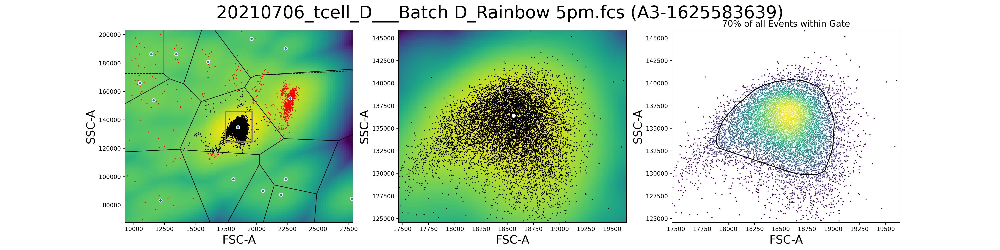

In [9]:
PIL.Image.open(find_matching_file(os.path.join(data_path, "rainbow", "plot_gate"), f"20210706_tcell_D"))

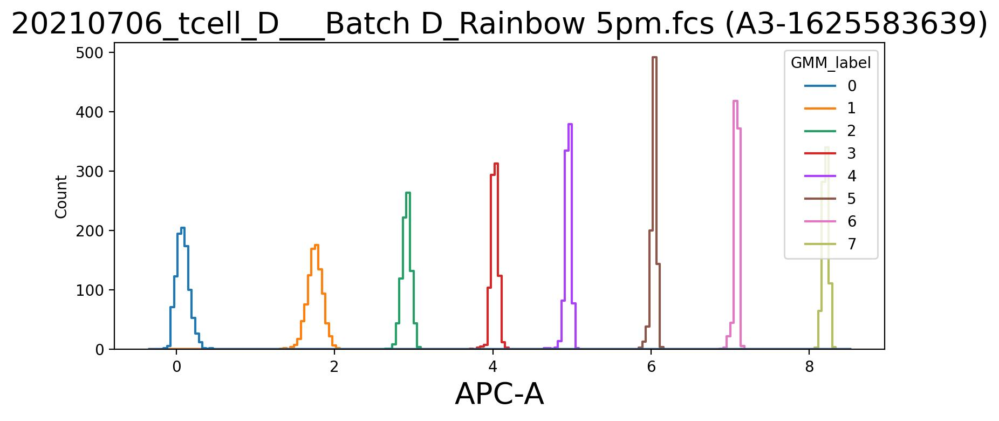

In [10]:
PIL.Image.open(find_matching_file(os.path.join(data_path, "rainbow", "plot_gmm_pre"), f"20210706_tcell_D"))

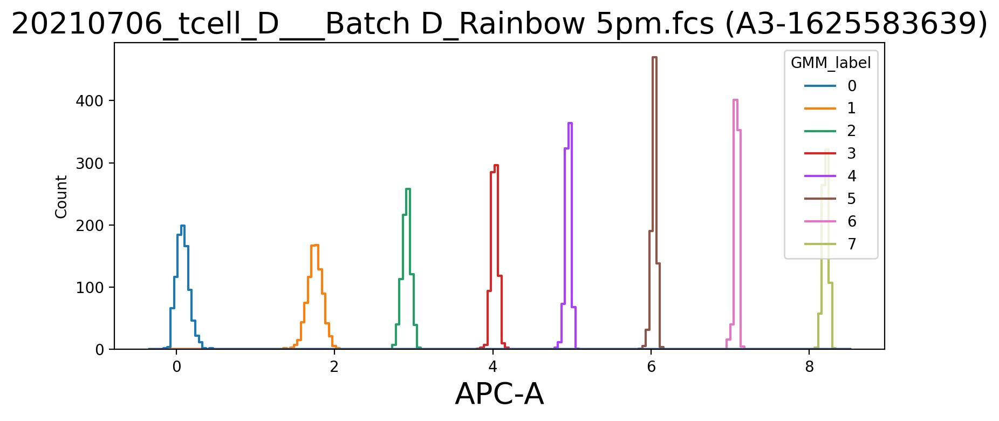

In [11]:
PIL.Image.open(find_matching_file(os.path.join(data_path, "rainbow", "plot_gmm_post"), f"20210706_tcell_D"))

Usually, our automated gating approach should yield reasonable results. However, some cytometers will split the singlet peak into two adjacent peaks etc., so cytovanni.gating.gate_scatter_bead_sample also implements two options 'robust' and 'very robust' that should be able to deal with this. As a fallback, it is also possible to do the gating manually beforehand and skip this step.

In [19]:
?cytovanni.gating.gate_scatter_bead_sample

Signature:
cytovanni.gating.gate_scatter_bead_sample(
    adata,
    gatechannels=None,
    plot=False,
    plotpath='',
    apply=True,
    titlefct=<function <lambda> at 0x14f972651300>,
    robust=False,
    very_robust=False,
)
Docstring:
Gate bead sample, using the same approach as AutoSpill.

:param adata: AnnData. The sample.

:param gatechannels: list or None. The two channels to use for the scatter gating, if None defaults to output of get_default_scatter_gate_channels() from cytometer configuration.

:param plot: bool. Whether to show the corresponding summary plot.

:param plotpath: str. Path to save the summary plot to.

:param apply: bool. Whether to apply the gating directly, or only store in 'keepmask_RB_scatter'.

:param titlefct: lambda. Function to get plot title from adata, set arbitrary name by passing (lamba x: "name").

:param robust: bool. Some beads have patterns like two close peaks instead of only one etc., the robust version changes some parameters to accomod

Depending on how clean the rainbow beads already are, the additional GMM gating step can also be skipped.

### Fit Rainbow Mixture Model

Now we first read the cleaned data.

In [20]:
files = list(filter(lambda x: x.endswith(".h5ad"), os.listdir(os.path.join(data_path, "rainbow", "data"))))
rb_adatas = [cytovanni.io.read_rainbow_h5ad(os.path.join(data_path, "rainbow", "data", file)) for file in tqdm(files, mininterval=1)]
rb_adatas.sort(key=lambda ad: ad.uns["UTC"])

100%|██████████| 113/113 [00:03<00:00, 28.42it/s]


And then fit the full rainbow mixture model. All the necessary metadata was already added in the previous step.

15:52:42 - Initializing Dataset
15:52:43 - Fit Initialization


100%|██████████| 1000/1000 [01:50<00:00,  9.02it/s, nll=27.5]


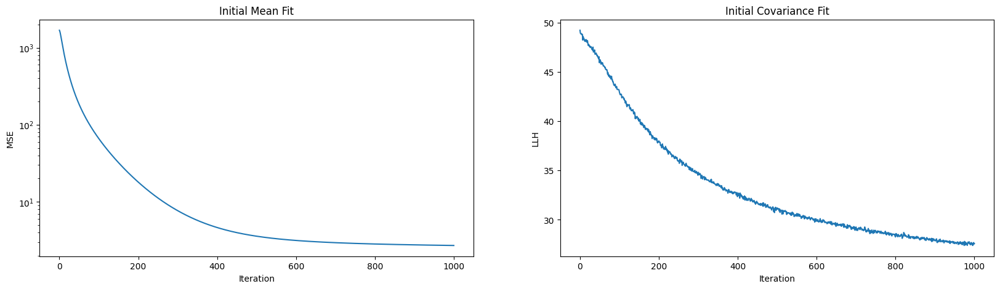

15:54:44 - Full Model Fit


100%|██████████| 10000/10000 [17:51<00:00,  9.33it/s, nll=23.9]


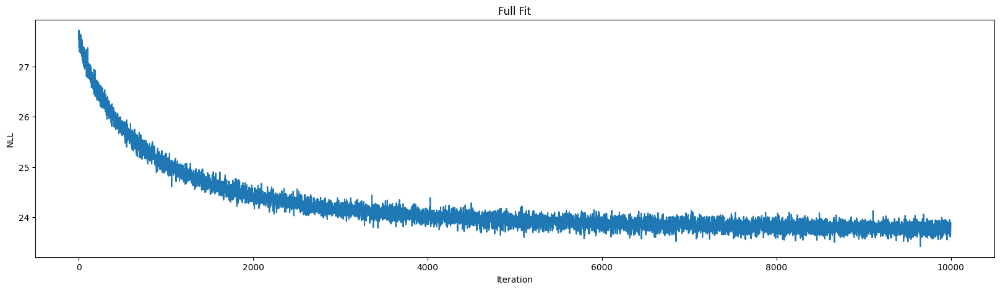

In [18]:
RBInt = cytovanni.rainbow.RainbowCalibrator(rb_adatas)
RBInt.fit_fluorescence()

Save the trained model.

In [19]:
RBInt.save(os.path.join(data_path, "rainbow", "RBInt.pt"))

The best way of assessing the quality of the fit is to look at histograms of the rainbow beads. The plot below shows the raw fluorescence on the left, and the fully integrated rainbow beads on the right. The model internally also allows an additional shift, as the background noise may slightly change between measurement days. However, this parameter is not used when calibrating the other data, and the middle column below shows the rainbow beads when only the calibration that is used for the other samples is used. The x-Axis is in units of fluroescence after applying an ArcSinh transformation.

As this example mixes two different lots of rainbow beads, we plot them separately.

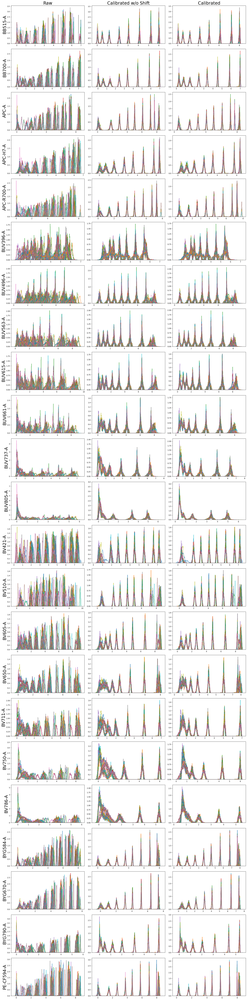

In [20]:
cytovanni.rainbow.plot_eval_calibration(RBInt, [ad for ad in rb_adatas if ad.uns["rainbow_type"]=="1055831"])
plt.savefig(os.path.join(data_path, "rainbow", "RBInt_fit_overview_1055831.pdf"))

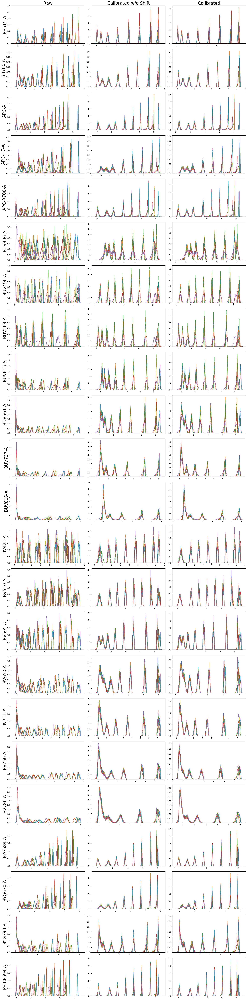

In [21]:
cytovanni.rainbow.plot_eval_calibration(RBInt, [ad for ad in rb_adatas if ad.uns["rainbow_type"]=="3285117"])
plt.savefig(os.path.join(data_path, "rainbow", "RBInt_fit_overview_3285117.pdf"))

Note that for some channels (BV421-A), the calibration works across all populations. However, for others (APC-A) the highest rainbow bead populations are not within the linear range of the detector, and so are not aligned with the other batches even after a successfull calibration.

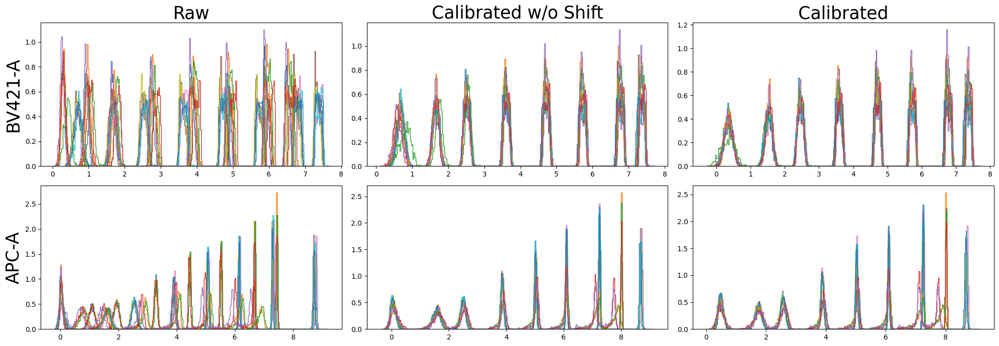

In [22]:
cytovanni.rainbow.plot_eval_calibration(RBInt, [ad for ad in rb_adatas if ad.uns["rainbow_type"]=="3285117"], channels=["BV421-A", "APC-A"])

### Extend Rainbow Mixture Model

It is also possible to extend an already fit model. By default, .fit_fluorescence freezes all already trained parameters after training is finished, so already present batches are not affected by adding new ones.

For example, we could first train on a subset of the measurements (some batches may not yet be recorded):

16:33:49 - Initializing Dataset
16:33:50 - Fit Initialization


100%|██████████| 1000/1000 [00:57<00:00, 17.31it/s, nll=25.9]


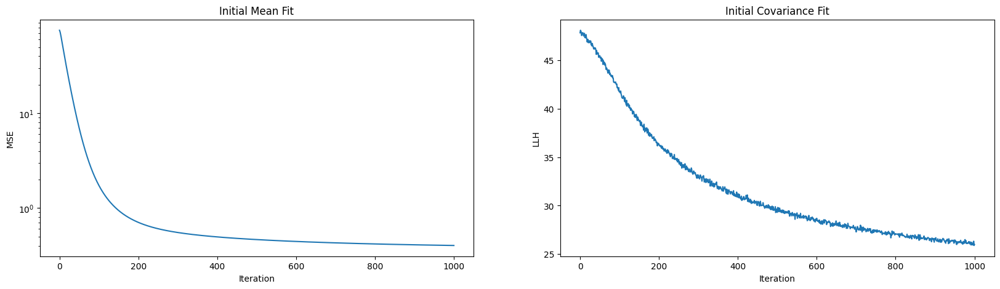

16:34:55 - Full Model Fit


100%|██████████| 10000/10000 [09:21<00:00, 17.80it/s, nll=22.3]


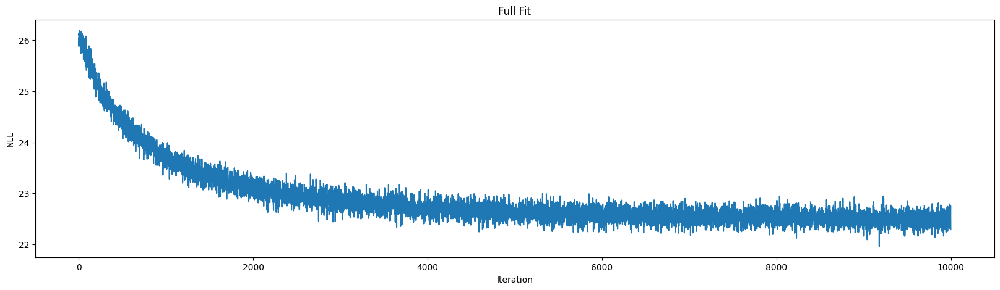

In [21]:
RBInt_ext = cytovanni.rainbow.RainbowCalibrator(rb_adatas[:60])
RBInt_ext.fit_fluorescence()

Afterwards, we extend the model using the rest of the rainbow bead measurements:

16:44:19 - Initializing Dataset
16:44:20 - Fit Initialization


100%|██████████| 1000/1000 [00:56<00:00, 17.60it/s, nll=22.5]


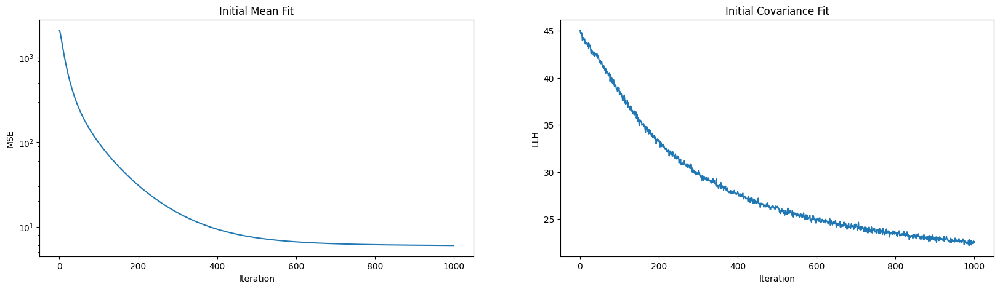

16:45:26 - Full Model Fit


100%|██████████| 10000/10000 [09:22<00:00, 17.77it/s, nll=18.7]


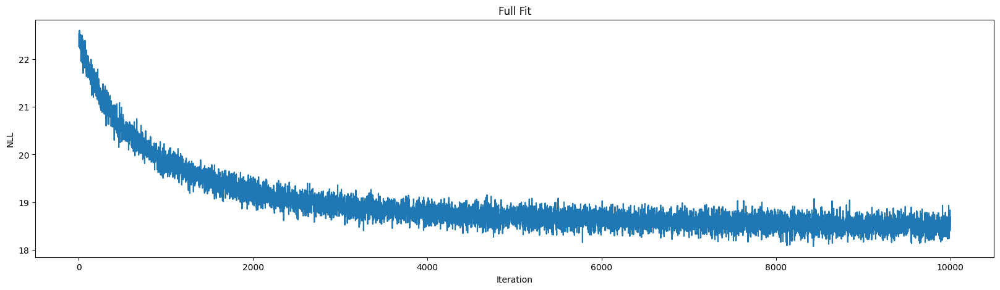

In [22]:
RBInt_ext.extend_fit(rb_adatas[60:])

In [23]:
RBInt_ext.save(os.path.join(data_path, "rainbow", "RBInt_extended.pt"))

In [24]:
RBInt_ext = cytovanni.rainbow.RainbowCalibrator.from_saved(os.path.join(data_path, "rainbow", "RBInt_extended.pt"))

Extracting all calibration factors from both models, they do not initially agree.

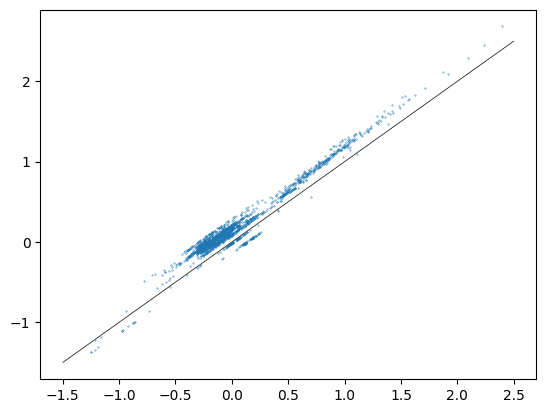

In [25]:
df_logfactors = np.log(RBInt.get_calibration_factors_all()) # already at mean 0
df_logfactors_ext = np.log(RBInt_ext.get_calibration_factors_all().loc[df_logfactors.index, df_logfactors.columns])

plt.plot([-1.5,2.5], [-1.5,2.5], color="black", linewidth=.5, zorder=-1)
plt.scatter(df_logfactors.to_numpy().flatten(), df_logfactors_ext.to_numpy().flatten(), s=.1)

However, this is caused by slightly different normalizations. If we normalize the logfactors from the extended model to make both comparable, they indeed agree:

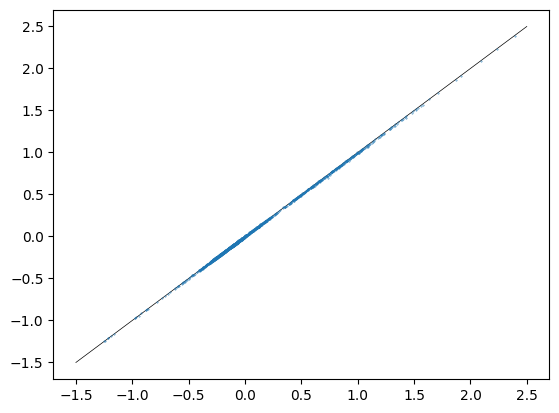

In [26]:
df_logfactors_ext_normed = df_logfactors_ext - df_logfactors_ext.to_numpy().mean(0, keepdims=True) # subtract mean from logfactors to get each channel to mean zero

plt.plot([-1.5,2.5], [-1.5,2.5], color="black", linewidth=.5, zorder=-1)
plt.scatter(df_logfactors.to_numpy().flatten(), df_logfactors_ext_normed.to_numpy().flatten(), s=.1)

Extending models like this also works if the newly added measurements are from a different lot or rainbow bead type (6 peak vs. 8 peak etc.). However, in this case it is important to measure both the old and the new beads together in at least one (ideally multiple) batches, otherwise the model has no way of knowing how to properly calibrate them.

## Applying the Calibration

In [5]:
RBInt = cytovanni.rainbow.RainbowCalibrator.from_saved(os.path.join(data_path, "rainbow", "RBInt.pt"))

As this is no longer sensible after the calibration, we will already apply some gates that filter out events in the non-linear range of the detectors here.

In [6]:
# we apply two generic gates that filter out all events in the non-linear range of the detectors to all samples
gate_minmax_scatter = cytovanni.gating.MinMaxGate(["FSC-A", "FSC-H", "SSC-A", "SSC-H"], 0, 4e5, layer="raw")
# the gate below applies a lower limit of -1e3 and an upper limit of 1.5 * cytoconfig.max_linear_range to cytoconfig.channels_fluorescence
gate_minmax_fluorescence = cytovanni.gating.FluorescenceMinMaxGate(cytoconfig, -1e3, 1.5, layer="raw")
gates_minmax = [gate_minmax_scatter, gate_minmax_fluorescence]

### Samples

We now apply the calibration to all samples. For simplicity, we will simply copy the full folder structure that contains the raw .fcs files, where all other files are simply copied, while for .fcs files we write a calibrated version of the original file. See the {doc}`tutorial with fixed spectra <../integration_fixed-spectra/integration_fixed-spectra-rainbow>` for more examples of how to use the trained model.

Note that we now already exclude events with fluorescence/scatter values in the non-linear range. This is fine for the actual samples, but for the rainbow beads the resulting files will no longer contain all eight peaks. However, this does not matter as we already processed them.

In [7]:
import shutil

def copy_fct(RBInt, src_path, dst_path):
    # if .fcs file make standardized version
    if src_path.endswith('.fcs'):
        RBInt.make_calibrated_fcs(src_path, dst_path, cytoconfig, gates=gates_minmax)
    # else just copy
    else:
        shutil.copy2(src_path, dst_path)

def copy_tree_with_processing(RBInt, src_dir, dst_dir):
    it = tqdm()
    for root, dirs, files in os.walk(src_dir):
        rel_path = os.path.relpath(root, src_dir)
        dst_root = os.path.join(dst_dir, rel_path)
        os.makedirs(dst_root, exist_ok=True)

        for file in files:
            src_path = os.path.join(root, file)
            dst_path = os.path.join(dst_root, file)
            copy_fct(RBInt, src_path, dst_path)
            it.update(1)
    it.close()

In [10]:
copy_tree_with_processing(RBInt,
                          os.path.join(raw_data_path, "raw_fcs"),
                          os.path.join(data_path, "calibrated_fcs"))

318it [05:22,  1.01s/it]


### Single Stain Spectra

In [ ]:
import shutil
shutil.copytree(os.path.join(raw_data_path, "single_stain"), os.path.join(data_path, "single_stain"))  

There are two main ways of dealing with single stain spectra. The first would be applying the rainbow calibration to the .fcs files before extracting the spectra, e.g. with AutoSpill, in which case they would then already be calibrated. 

In our case, the spectra were extracted before the calibration, into files `spectra.csv` where the index corresponds to the channel, and the column to the used dye:

In [12]:
pd.read_table(os.path.join(data_path, "single_stain", "HD7_Compensation_20231117_tcell", "spectra.csv"), sep=",", index_col=0)

,FITC,BB700,APC,APC-H7,APC-R700,BUV395,BUV496,BUV563,BUV615,BUV661,BUV805,BV421,BV650,BV711,BV750,BV786,PE (BioLegend),PE-Cy5,PE-Cy7 (BD),PE-CF594
BB515-A,1.000000,0.000295,0.000047,0.000139,0.000061,0.000182,0.005367,0.016005,0.000049,0.000062,0.000208,0.000051,0.000083,0.000047,0.000061,0.000077,0.002881,0.000315,0.000507,0.000463
BB700-A,0.016813,1.000000,0.010338,0.000669,0.027626,0.000402,0.000384,0.014387,0.009629,0.012456,0.001108,0.000092,0.006121,0.063400,0.012054,0.000783,0.061243,0.654244,0.019059,0.263418
APC-A,0.000099,0.235490,1.000000,0.017945,0.118363,0.000064,0.000026,0.000152,0.004205,0.643577,0.001170,0.000000,0.121473,0.031952,0.000215,0.001183,0.000208,0.523043,0.000353,0.002347
APC-H7-A,0.000485,0.135926,0.135635,1.000000,0.231248,0.000168,0.000023,0.000152,0.000685,0.088507,0.125408,0.000022,0.017416,0.089608,0.059567,0.059463,0.000051,0.071743,0.095360,0.000398
APC-R700-A,0.000281,0.421736,0.548649,0.052398,1.000000,0.000140,0.000051,0.000518,0.002361,0.387012,0.009073,0.000041,0.074467,0.298145,0.049768,0.008472,0.000177,0.268596,0.007641,0.001313
BUV396-A,0.000421,0.000406,0.000131,0.000220,0.000000,1.000000,0.069953,0.167039,0.095953,0.085031,0.284083,0.005491,0.000289,0.003358,0.003843,0.003289,0.000075,0.000112,0.000000,0.000066
BUV496-A,0.298383,0.003957,0.001003,0.001723,0.000317,0.184588,1.000000,0.129769,0.055942,0.066476,0.191548,0.187951,0.004148,0.036552,0.033199,0.036660,0.000749,0.000871,0.000366,0.000569
BUV563-A,0.015692,0.000776,0.000179,0.000332,0.000073,0.005547,0.063693,1.000000,0.096859,0.003708,0.010482,0.006313,0.001157,0.001377,0.001460,0.001526,0.125682,0.001158,0.001470,0.009018
BUV615-A,0.007049,0.000722,0.001257,0.000333,0.000092,0.002834,0.033787,0.556478,1.000000,0.040172,0.008837,0.003117,0.038450,0.000810,0.000950,0.001052,0.054138,0.001189,0.000772,0.118903
BUV661-A,0.001938,0.185490,0.151886,0.002739,0.011292,0.001137,0.010585,0.149520,0.481472,1.000000,0.005456,0.001099,0.259880,0.043553,0.000931,0.001702,0.016020,0.152713,0.000380,0.056969


As the spectra were recorded for different panels, there is also a panel_meta.csv with some metadata for each measurement:

In [13]:
pd.read_table(os.path.join(data_path, "single_stain", "HD7_Compensation_20231117_tcell", "panel_meta.csv"), sep=",", index_col=0)

,channel,dye,antigen
FITC,BB515-A,FITC,CD45RA
BB700,BB700-A,BB700,CD69
APC,APC-A,APC,CD197
APC-H7,APC-H7-A,APC-H7,CD3
APC-R700,APC-R700-A,APC-R700,CD127
BUV395,BUV396-A,BUV395,CD4
BUV496,BUV496-A,BUV496,CD8
BUV563,BUV563-A,BUV563,CD19|71|33
BUV615,BUV615-A,BUV615,CD314
BUV661,BUV661-A,BUV661,CXCR3


We named the different measurements, so we can assign each panel to a given rainbow bead batch:

In [14]:
meta_run = pd.read_table(os.path.join(data_path, "single_stain", "meta_run.csv"), sep=",", index_col=0)
meta_run

,run,rainbow_batch
0,HD7_CompensationM_20230904_Sidentity1,20230904_comp_Sidentity1
1,HD7_CompensationM_20230904_Sidentity2,20230904_comp_Sidentity2
2,HD7_CompensationM_20230915_Stcell2,20230915_comp_Stcell2
3,HD7_CompensationM_20230920_Stcell3,20230920_comp_Stcell3
4,HD7_CompensationM_20230921_Sidentity,20230921_comp_Sidentity
5,HD7_CompensationM_20230921_Stcell,20230921_comp_Stcell
6,HD7_CompensationM_20240411_Sidentity,20240411_comp_Sidentity
7,HD7_CompensationM_20240411_Stcell,20240411_comp_Stcell
8,HD7_CompensationM_20240411_Stcell_failed,20240411_comp_Stcell_failed
9,HD7_CompensationM_20240514_Sidentity,20240514_comp_Sidentity


We can then iterate over all measurements, using `RBInt.get_calibrated_spectra` to calibrate the spectra, and save the correct ones as `spectra_calibrated.csv`:

In [16]:
for name, row in tqdm(meta_run.iterrows(), total=len(meta_run)):
    spectra_raw = pd.read_table(os.path.join(data_path, "single_stain", row["run"], "spectra.csv"), sep=",", index_col=0)
    spectra_calibrated = RBInt.get_calibrated_spectra(spectra_raw, row["rainbow_batch"], spectral=False)
    spectra_calibrated.to_csv(os.path.join(data_path, "single_stain", row["run"], "spectra_calibrated.csv"))

100%|██████████| 23/23 [00:00<00:00, 51.48it/s]


### AutoSpill

AutoSpill exports the spectra such that rows correspond to dyes:

In [17]:
pd.DataFrame([pd.read_table(os.path.join(data_path, "single_stain", "HD7_Compensation_20231117_tcell", "autospill_spillover.csv"), sep=",", index_col=0)
              .loc["BB700-A"],
              pd.read_table(os.path.join(data_path, "single_stain", "HD7_Compensation_20231117_tcell", "spectra.csv"), sep=",", index_col=0)
              ["BB700"]],
              index=["AutoSpill Row", "Custom Column"]).T

,AutoSpill Row,Custom Column
APC-A,0.235666,0.235490
APC-H7-A,0.135725,0.135926
APC-R700-A,0.420929,0.421736
BB515-A,0.000354,0.000295
BB700-A,1.000000,1.000000
BUV396-A,0.000470,0.000406
BUV496-A,0.004153,0.003957
BUV563-A,0.000868,0.000776
BUV615-A,0.000782,0.000722
BUV661-A,0.187756,0.185490


We therefore need to make sure to transpose the spectra before calibrating them:

In [18]:
run = "HD7_Compensation_20231117_tcell"
rb_batch = "20231117_comp_tcell"

spectra_raw = pd.read_table(os.path.join(data_path, "single_stain", run, "autospill_spillover.csv"), sep=",", index_col=0)
spectra_calibrated = RBInt.get_calibrated_spectra(spectra_raw.T, rb_batch, spectral=False)

We can then rename the columns from the default channel names that AutoSpill uses to our marker names, and save the spectra in the same format we used for our spectra above:

In [19]:
channel_dye_key = {v:k for k,v in pd.read_table(os.path.join(data_path, "single_stain", "HD7_Compensation_20231117_tcell", "panel_meta.csv"), sep=",", index_col=0)["channel"].to_dict().items()}
spectra_calibrated = spectra_calibrated.rename(columns=channel_dye_key)
spectra_calibrated.to_csv(os.path.join(data_path, "single_stain", run, "autospill_spillover_calibrated.csv"))